In [ ]:
import torch
#import torch.nn as nn
#import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
#import os


Uruchomione na: cpu


In [ ]:

import random
import numpy as np


CONFIG = {
    "seed": 42,
    "image_size": 128,
    "batch_size": 32,
    "num_workers": 0,
    "learning_rate": 0.001,
    "epochs": 20,
}

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["seed"])


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Uruchomione na:", device)
print("Seed:", CONFIG["seed"])
print("Konfiguracja:", CONFIG)


Uruchomione na: cpu
Seed: 42
Konfiguracja: {'seed': 42, 'image_size': 128, 'batch_size': 32, 'num_workers': 0, 'learning_rate': 0.001, 'epochs': 20}


In [33]:
rest_transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize(
    mean=[0.5, 0.5, 0.5],
    std=[0.5, 0.5, 0.5])
])

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(128, scale=(0.8, 1.0)), 
    transforms.RandomHorizontalFlip(p=0.3),
    transforms.RandomRotation(15), 
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5])
])

In [34]:
from torchvision.datasets import ImageFolder

train = ImageFolder("dataset/train", transform=train_transform)
test = ImageFolder("dataset/test", transform=rest_transform)
valid = ImageFolder("dataset/val", transform=rest_transform)

print("Klasy:", train.classes)
print("Wielkość train:", len(train))
print("Wielkość test:", len(test))
print("Wielkość valid:", len(valid))

train_loader = DataLoader(train, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid, batch_size=32)
test_loader = DataLoader(test, batch_size=32)

Klasy: ['astilbe', 'bellflower', 'black_eyed_susan', 'calendula', 'california_poppy', 'carnation', 'common_daisy', 'coreopsis', 'dandelion', 'iris', 'rose', 'sunflower', 'tulip', 'water_lily']
Wielkość train: 10741
Wielkość test: 1424
Wielkość valid: 1433


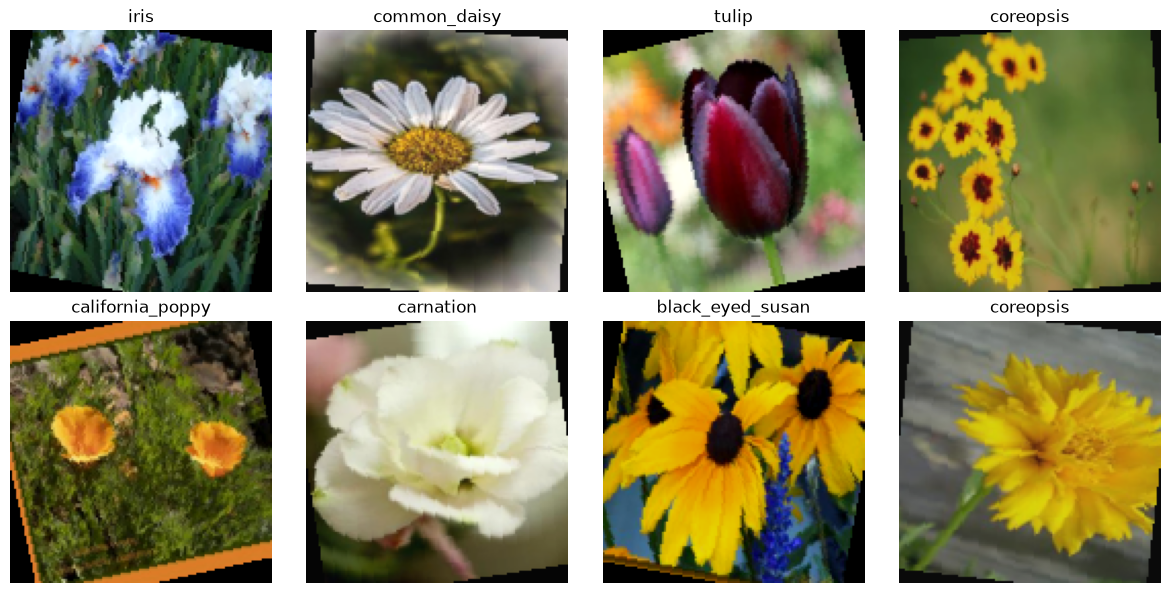

In [35]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # Odwrócenie normalizacji
    img = images[i] * 0.5 + 0.5

    img = img.permute(1, 2, 0)

    ax.imshow(img)
    ax.set_title(train.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import hashlib

def get_image_hashes(dataset):
    hashes = {}

    for path, label in dataset.samples:
        with open(path, "rb") as f:
            file_hash = hashlib.sha256(f.read()).hexdigest()

        hashes[file_hash] = path

    return hashes


train_hashes = get_image_hashes(train)
valid_hashes = get_image_hashes(valid)
test_hashes = get_image_hashes(test)



train_valid = set(train_hashes) & set(valid_hashes)
train_test = set(train_hashes) & set(test_hashes)
valid_test = set(valid_hashes) & set(test_hashes)

print("Duplikaty train-valid:", len(train_valid))
print("Duplikaty train-test:", len(train_test))
print("Duplikaty valid-test:", len(valid_test))

Duplikaty train-valid: 0
Duplikaty train-test: 0
Duplikaty valid-test: 0


In [37]:
print("\nDuplikaty train-valid:")
for h in train_valid:
    print(train_hashes[h])
    print(valid_hashes[h])

print("\nDuplikaty train-test:")
for h in train_test:
    print(train_hashes[h])
    print(test_hashes[h])

print("\nDuplikaty valid-test:")
for h in valid_test:
    print(valid_hashes[h])
    print(test_hashes[h])


Duplikaty train-valid:

Duplikaty train-test:

Duplikaty valid-test:


In [ ]:
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score
import torch


print("\nTest")

model.eval() 

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        
        _, predicted = outputs.max(1)
        
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        

correct = sum([p == l for p, l in zip(all_preds, all_labels)])
accuracy = 100. * correct / len(all_labels)

precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)


print(f"Accuracy: {accuracy:.2f}%")
print(f"Precision:   {precision:.4f}")
print(f"Recall:       {recall:.4f}")
print(f"F1-Score:               {f1:.4f}")
print("-" * 50)

print("\nDla klas:")


class_names = test.classes 

raport = classification_report(all_labels, all_preds, target_nameswi=class_names, zero_division=0)
print(raport)

